# 2. Train a TDE-HMM

This notebook trains the model on the preprocessed recordings from
`1_preprocess.ipynb` from several random seeds, checks that the seeds agree,
labels the states in a reproducible order, and saves the chosen model in the
same format as the released HUP model in `hup-model/`.

## The model

A **time-delay embedded hidden Markov model** (TDE-HMM), trained with
[osl-dynamics](https://github.com/OHBA-analysis/osl-dynamics):

1. **Time-delay embedding.** Each sample of a channel is replaced by the
   vector of its 11 neighbouring samples (110 ms at 100 Hz). The covariance of
   this vector is the channel's autocovariance over +/-50 ms, which encodes its
   power spectrum.
2. **PCA.** The 11-dimensional embedded signal is reduced to 6 principal
   components (fit on the training data).
3. **Standardisation.** Each channel's components are z-scored on their own, so
   the states describe transient departures from the channel's own average
   spectrum rather than differences between channels.
4. **HMM.** Each state is a zero-mean Gaussian with its own covariance in the
   6-dimensional space, i.e. its own power spectrum; a transition matrix
   governs switching between states. Inference gives the probability of each
   state at every time point.

| Setting | Value |
|---|---|
| sampling frequency | 100 Hz |
| embedding window | 11 samples (110 ms) |
| PCA components | 6 |
| states | 4 |
| sequence length / batch size | 200 samples / 256 sequences |
| learning rate / epochs | 0.01 / 20 |

These are the released model's settings. The released model was trained on 45
subjects (about 190 channel-hours) on a GPU; for this small example each run
takes a few minutes on a laptop CPU.

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

STATE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

from scipy.optimize import linear_sum_assignment

from osl_dynamics.analysis import spectral
from osl_dynamics.data import Data
from osl_dynamics.inference import modes
from osl_dynamics.models.hmm import Config, Model
from osl_dynamics.utils.misc import set_random_seed

In [2]:
SFREQ = 100
N_EMBEDDINGS = 11
N_PCA_COMPONENTS = 6
SEQUENCE_LENGTH = 200
BATCH_SIZE = 256
LEARNING_RATE = 0.01
N_EPOCHS = 20

N_STATES = 4
SEEDS = [0, 1, 2]                      # random seeds (independent trainings)

DATA_DIR = Path("data/preprocessed")
TRAIN_SUBJECTS = ["sub-HUP060", "sub-HUP112", "sub-HUP133", "sub-HUP173"]
HELD_OUT_SUBJECTS = ["sub-HUP116", "sub-HUP117"]

## 1. Load the data and split by subject

Hold out whole subjects, not channels: channels from one subject are similar,
so held-out channels from a training subject would not show how well the model
describes new patients. The held-out data are used to compare models and to
label the states.

Each bipolar channel is one `(n_samples, 1)` array: the model is
single-channel, so every channel is a separate time series.

In [3]:
def load(subjects):
    arrays, names = [], []
    for subject in subjects:
        z = np.load(DATA_DIR / f"{subject}.npz")
        arrays += [ch[:, None] for ch in z["data"]]
        names += [f"{subject}|{ch}" for ch in z["channels"]]
    return arrays, names


train_arrays, train_names = load(TRAIN_SUBJECTS)
held_out_arrays, held_out_names = load(HELD_OUT_SUBJECTS)
print(f"training: {len(train_arrays)} channels from {len(TRAIN_SUBJECTS)} subjects, "
      f"{sum(len(a) for a in train_arrays) / SFREQ / 3600:.1f} channel-hours")
print(f"held out: {len(held_out_arrays)} channels from {len(HELD_OUT_SUBJECTS)} subjects")

training: 151 channels from 4 subjects, 12.6 channel-hours
held out: 72 channels from 2 subjects


## 2. Prepare the data

`tde_pca` time-delay embeds each channel and projects it onto the principal
components, which are computed on the training data only; the held-out data
use the same components. `standardize` then z-scores each channel's components.
The PCA components are part of the model and are saved with it.

In [4]:
train = Data(train_arrays)
train.prepare({
    "tde_pca": {"n_embeddings": N_EMBEDDINGS, "n_pca_components": N_PCA_COMPONENTS},
    "standardize": {},
})
pca_components = train.pca_components                     # (N_EMBEDDINGS, N_PCA_COMPONENTS)

held_out = Data(held_out_arrays)
held_out.prepare({
    "tde_pca": {"n_embeddings": N_EMBEDDINGS, "pca_components": pca_components},
    "standardize": {},
})
print(f"explained variance of the {N_PCA_COMPONENTS} components: {100 * train.explained_variance:.0f}%")

[15:02:42] Explained variance: 98.3%


explained variance of the 6 components: 98%


## 3. Train from several seeds

HMM training can end in different solutions depending on the random
initialisation, so we train the model from every seed in `SEEDS` and for each
run record

- the **free energy** (the variational bound on the negative log evidence,
  lower is better) on the training and the held-out subjects, and
- the **state probabilities** on the held-out subjects, to compare the
  solutions of different seeds.

In [5]:
def train_hmm(n_states, seed):
    set_random_seed(seed)
    config = Config(
        n_states=n_states, n_channels=N_PCA_COMPONENTS, sequence_length=SEQUENCE_LENGTH,
        learn_means=False, learn_covariances=True,
        batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, n_epochs=N_EPOCHS,
    )
    model = Model(config)
    model.train(train, verbose=0)
    return model


runs = {}
for seed in SEEDS:
    model = train_hmm(N_STATES, seed)
    runs[seed] = dict(
        model=model,
        fe_train=float(model.free_energy(train)),
        fe_held_out=float(model.free_energy(held_out)),
        alpha=model.get_alpha(held_out),
    )
    print(f"seed {seed}: free energy train {runs[seed]['fe_train']:.3f}, "
          f"held out {runs[seed]['fe_held_out']:.3f}", flush=True)

[15:02:42] Setting random seed to 0


[15:02:42] Random state time course initialization


[15:02:56] Using initialization 0 (loss=7.88)


[15:04:32] Free energy: 7.6618


seed 0: free energy train 7.662, held out 7.465


[15:04:52] Setting random seed to 1


... (5 outputs left out)

[15:07:18] Random state time course initialization


[15:07:31] Using initialization 2 (loss=7.882)


[15:09:23] Free energy: 7.6619


seed 2: free energy train 7.662, held out 7.465


## 4. Compare the runs

If different seeds find the same states, the solution is a property of the
data rather than of the initialisation. We take the run with the lowest
held-out free energy as the reference, match the other runs' states to it
(Hungarian assignment on the correlation of the state probabilities over the
held-out data), and report the fraction of time points assigned to the same
most-probable state.

In [6]:
def agreement(alpha_a, alpha_b):
    """Match states of run b to run a; return (fraction of samples with the same
    most-probable state, matched-state correlations)."""
    A = np.concatenate(alpha_a); B = np.concatenate(alpha_b)
    corr = np.corrcoef(A.T, B.T)[:A.shape[1], A.shape[1]:]
    rows, cols = linear_sum_assignment(-corr)
    to_a = np.argsort(cols)                       # state of run b -> matched state of run a
    same = np.mean(to_a[B.argmax(1)] == A.argmax(1))
    return same, corr[rows, cols]


reference = min(SEEDS, key=lambda s: runs[s]["fe_held_out"])
rows = []
for seed in SEEDS:
    same, corr = agreement(runs[reference]["alpha"], runs[seed]["alpha"])
    rows.append(dict(seed=seed, free_energy_train=runs[seed]["fe_train"],
                     free_energy_held_out=runs[seed]["fe_held_out"],
                     reference=seed == reference, same_state_as_reference=same,
                     min_state_correlation=corr.min()))
comparison = pd.DataFrame(rows)
comparison.round(3)

,seed,free_energy_train,free_energy_held_out,reference,same_state_as_reference,min_state_correlation
0,0,7.662,7.465,False,0.995,1.0
1,1,7.662,7.465,True,1.000,1.0
2,2,7.662,7.465,False,0.997,1.0


A run that agrees with the reference on well over 90% of samples has found the
same solution. If the seeds disagree, train more seeds and look at what
distinguishes the solutions before choosing. We keep the run with the lowest
held-out free energy.

The number of states is a choice. In the paper, four states was the largest
number for which every seed converged to the same solution in both cohorts
(99% agreement), while five and six states were only partly reproducible, and
the downstream results did not depend on the choice when checked at three and
five states. To repeat that check on your data, rerun this notebook with other
values of `N_STATES`.

In [7]:
best = runs[reference]
model, alpha = best["model"], best["alpha"]
print(f"chosen: seed {reference} (held-out free energy {best['fe_held_out']:.3f})")

chosen: seed 1 (held-out free energy 7.465)


## 5. Label the states

The order of the states after training is arbitrary, so we label them by a
fixed rule computed from their power spectra on the held-out subjects, the same
rule as the released model:

- **State 1** is the state with the most 13-45 Hz power (the broadband state;
  in epilepsy recordings this is the state that captures interictal
  discharges),
- the remaining states follow in **descending 1-4 Hz power**.

State spectra are estimated with a multitaper method weighted by the state
probabilities. The model's parameters (covariances, transition matrix, initial
state probabilities) are then permuted so that the saved model's states are
already in this order; the check confirms the permuted model gives the same
state probabilities, renumbered.

In [8]:
signal = held_out.trim_time_series(sequence_length=SEQUENCE_LENGTH, prepared=False)
freqs, psd = spectral.multitaper_spectra(
    data=signal, alpha=alpha, sampling_frequency=SFREQ, frequency_range=[1, 45], calc_coh=False,
)
psd = np.squeeze(psd)                              # (n_channels, n_states, n_freqs)


def band_power(mean_psd, lo, hi):
    m = (freqs >= lo) & (freqs <= hi)
    return np.trapezoid(mean_psd[:, m], freqs[m], axis=-1)


mean_psd = psd.mean(axis=0)
broadband = band_power(mean_psd, 13, 45)
delta = band_power(mean_psd, 1, 4)
first = int(np.argmax(broadband))
order = np.array([first] + [k for k in np.argsort(delta)[::-1] if k != first])
print("trained state shown as State 1..N:", order.tolist())

# permute the model so its states are in this order
initial_state_probs = model.get_initial_state_probs()[order]
model.set_covariances(model.get_covariances()[order])
model.set_trans_prob(model.get_trans_prob()[np.ix_(order, order)])
model.model.get_layer("hid_state_inf").layers[0].tensor.assign(initial_state_probs.astype(np.float32))

reordered = model.get_alpha(held_out)
assert all(np.allclose(new, old[:, order], atol=1e-4) for new, old in zip(reordered, alpha))
alpha, psd = reordered, psd[:, order]
STATE_NAMES = [f"State {k + 1}" for k in range(N_STATES)]

trained state shown as State 1..N: [3, 1, 0, 2]


## 6. Describe the states

State spectra (mean over the held-out channels) and the summary statistics of
the state dynamics: fractional occupancy (fraction of time in the state), mean
lifetime (duration of a visit), mean interval (time between visits) and
switching rate (visits per second).

,Fractional occupancy,Mean lifetime (ms),Mean interval (ms),Switching rate (/s)
State 1,0.147,147.824,1014.664,1.009
State 2,0.269,181.244,767.371,1.549
State 3,0.274,190.772,509.682,1.460
State 4,0.311,169.054,416.052,1.801


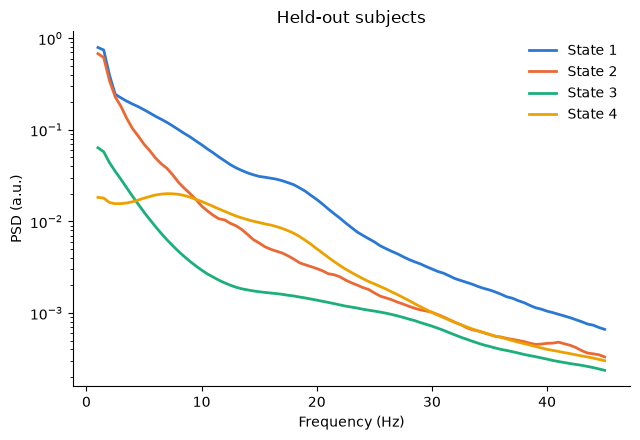

In [9]:
stc = modes.argmax_time_courses(alpha)
fo = modes.fractional_occupancies(stc)
lt = modes.mean_lifetimes(stc, sampling_frequency=SFREQ)
iv = modes.mean_intervals(stc, sampling_frequency=SFREQ)
sr = modes.switching_rates(stc, sampling_frequency=SFREQ)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k in range(N_STATES):
    ax.semilogy(freqs, psd[:, k].mean(axis=0), color=STATE_COLORS[k], lw=2, label=STATE_NAMES[k])
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (a.u.)", title="Held-out subjects")
ax.legend(frameon=False)
fig.tight_layout()

pd.DataFrame({
    "Fractional occupancy": fo.mean(axis=0),
    "Mean lifetime (ms)": 1000 * np.nanmean(lt, axis=0),
    "Mean interval (ms)": 1000 * np.nanmean(iv, axis=0),
    "Switching rate (/s)": sr.mean(axis=0),
}, index=STATE_NAMES).round(3)

## 7. Save the model

The model is saved in the layout of `hup-model/`: the osl-dynamics model
(`config.yml`, `model.weights.h5`), the PCA components, and a
`model_info.json` with the settings that `3_apply.ipynb` reads. The states are
stored in the labelled order.

In [10]:
MODEL_DIR = Path("my_model")
model.save(MODEL_DIR)
np.save(MODEL_DIR / "pca_components.npy", pca_components)
np.save(MODEL_DIR / "covs.npy", model.get_covariances())
np.save(MODEL_DIR / "trans_prob.npy", model.get_trans_prob())
info = {
    "model": "single-channel time-delay-embedded hidden Markov model (TDE-HMM)",
    "n_states": N_STATES,
    "sampling_frequency_hz": SFREQ,
    "n_embeddings": N_EMBEDDINGS,
    "n_pca_components": N_PCA_COMPONENTS,
    "sequence_length": SEQUENCE_LENGTH,
    "learn_means": False,
    "state_order": ("States are in the canonical order, defined on the held-out subjects: the broadband "
                    "state (most 13-45 Hz power) is State 1, the rest follow in descending 1-4 Hz power"),
    "training_subjects": TRAIN_SUBJECTS,
    "held_out_subjects": HELD_OUT_SUBJECTS,
    "n_epochs": N_EPOCHS,
    "seed": int(reference),
    "held_out_free_energy": best["fe_held_out"],
    "run_comparison": comparison.to_dict(orient="records"),
}
(MODEL_DIR / "model_info.json").write_text(json.dumps(info, indent=2))
print(sorted(p.name for p in MODEL_DIR.iterdir()))

['config.yml', 'covs.npy', 'model.weights.h5', 'model_info.json', 'pca_components.npy', 'trans_prob.npy']


## Scaling up

For a model you intend to rely on:

- **More subjects, not more channels per subject.** The released model used 25
  random bipolar channels from each of 45 subjects (SEEG and ECoG), about 190
  channel-hours; diversity across patients matters more than hours per patient.
- **More seeds.** The released model used 3 seeds per number of states,
  trained on a GPU. Each run on a laptop CPU takes minutes for this example and
  hours for a full cohort.
- **Choose the number of states by reproducibility**: train several numbers of
  states, keep the largest that every seed reproduces, and check that your
  downstream results do not hinge on the choice. Held-out free energy almost
  always keeps falling as states are added, so on its own it rarely picks a
  number.
- **Different embedding settings** change what the states are; longer windows
  give better frequency resolution but longer state lifetimes. The free energy
  is not comparable across embedding settings or datasets.